In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [18]:
#hyperparameters
input_size = 1
output_size = 1
num_epochs = 60

In [5]:
# Toy dataset
x_train = np.array([[3.3], [4.4], [5.5], [6.71], [6.93], [4.168], 
                    [9.779], [6.182], [7.59], [2.167], [7.042], 
                    [10.791], [5.313], [7.997], [3.1]], dtype=np.float32)

y_train = np.array([[1.7], [2.76], [2.09], [3.19], [1.694], [1.573], 
                    [3.366], [2.596], [2.53], [1.221], [2.827], 
                    [3.465], [1.65], [2.904], [1.3]], dtype=np.float32)

In [19]:
#线性模型
model = torch.nn.Linear(input_size, output_size)

In [8]:
#损失函数
criterion = torch.nn.MSELoss(size_average=False)  #均方误差损失函数

/opt/anaconda3/envs/ai/lib/python3.12/site-packages/torch/nn/modules/loss.py:48: UserWarning: size_average and reduce args will be deprecated, please use reduction='sum' instead.
  self.reduction: str = _Reduction.legacy_get_string(size_average, reduce)


In [20]:
#优化器
optimizer = torch.optim.SGD(model.parameters(), lr=0.0001)  #随机梯度下降优化器

In [ ]:
#训练模型
for epoch in range(num_epochs):
    # Convert numpy arrays to torch tensors
    inputs = torch.from_numpy(x_train)
    targets = torch.from_numpy(y_train)

    # 前向传播
    outputs = model(inputs)
    loss = criterion(outputs, targets)

    # 反向传播&优化
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    #注意，是先归零再优化，归零是在将上一轮的梯度清零，防止梯度累加。

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [10/60], Loss: 39.3122
Epoch [20/60], Loss: 5.0362
Epoch [30/60], Loss: 2.8994
Epoch [40/60], Loss: 2.7647
Epoch [50/60], Loss: 2.7547
Epoch [60/60], Loss: 2.7525


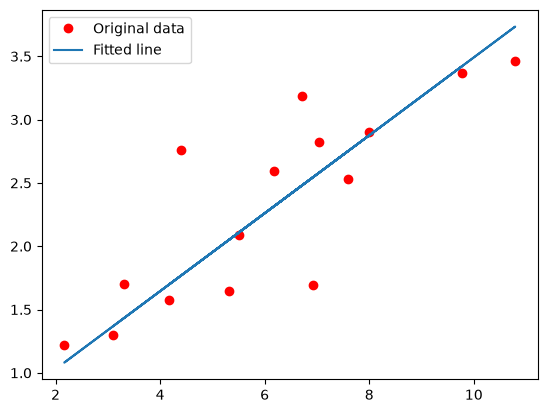

In [22]:
# Plot the graph
predicted = model(torch.from_numpy(x_train)).detach().numpy()
plt.plot(x_train, y_train, 'ro', label='Original data')
plt.plot(x_train, predicted, label='Fitted line')
plt.legend()
plt.show()